# M03-L03 — Algoritmos clássicos de classificação

Bem-vindo(a) de volta! Este notebook dá continuidade direta à M03-L02.

Nesta lição, você vai treinar seus primeiros classificadores de verdade, usando o padrão `instanciar → fit() → predict()` do scikit-learn, e comparar as predições de três algoritmos diferentes: Regressão Logística, Árvore de Decisão e KNN.

**Objetivos da lição.** Ao final, você deverá ser capaz de:

- explicar o que significa treinar um modelo de classificação;
- explicar o papel de `fit()` e de `predict()`;
- compreender intuitivamente Regressão Logística, Árvore de Decisão e KNN;
- instanciar, treinar e usar classificadores do scikit-learn;
- interpretar qualitativamente as predições produzidas pelos modelos;
- identificar erros comuns envolvendo treinamento, predição e uso incorreto de treino/teste.

**Arquivos necessários.** Os seguintes arquivos devem estar na mesma pasta deste notebook (ou no seu Google Drive, se estiver rodando no Colab):

- `X_treino.csv`
- `X_teste.csv`
- `y_treino.csv`
- `y_teste.csv`

Os quatro arquivos foram gerados por você ao final da M03-L02. Se não os encontrar, reabra e reexecute o notebook salvo daquela lição para gerá-los novamente.

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Retomando a M03-L02

Na lição passada, o Iris foi carregado com pandas, preparado e dividido em treino e teste com `train_test_split()`.

Ao final da M03-L02, os dados foram salvos em **quatro arquivos separados**:

- `X_treino.csv` — features usadas para treinar os modelos;
- `X_teste.csv` — features reservadas para gerar predições;
- `y_treino.csv` — rótulos correspondentes às linhas de `X_treino`;
- `y_teste.csv` — rótulos correspondentes às linhas de `X_teste`.

A divisão treino/teste já foi feita. **Não use `train_test_split()` novamente nesta lição.** Agora vamos apenas reabrir esses quatro arquivos e utilizá-los no treinamento dos classificadores.

## Exemplo guiado 1 — Carregando os quatro arquivos preparados na M03-L02

Vamos importar o pandas e reabrir os quatro arquivos.

Os arquivos `X_treino.csv` e `X_teste.csv` são tabelas com as features. Já `y_treino.csv` e `y_teste.csv` têm apenas a coluna `especie`; por isso, selecionamos essa coluna após a leitura para obter um vetor de rótulos.

In [4]:
import pandas as pd

X_train = pd.read_csv("X_treino.csv")
X_test = pd.read_csv("X_teste.csv")

y_train = pd.read_csv("y_treino.csv")["especie"]
y_test = pd.read_csv("y_teste.csv")["especie"]

X_train.head()

,comprimento_sepala,largura_sepala,comprimento_petala,largura_petala
0,5.0,3.4,1.6,0.4
1,6.3,3.3,4.7,1.6
2,5.1,3.4,1.5,0.2
3,4.8,3.0,1.4,0.1
4,6.7,3.1,4.7,1.5


Vamos conferir o tamanho dos quatro conjuntos e a distribuição das espécies nos rótulos, usando `shape` e `value_counts()`, já praticados na M03-L02.

In [5]:
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print("\nClasses no treino:")
print(y_train.value_counts())

print("\nClasses no teste:")
print(y_test.value_counts())

X_train: (120, 4)
y_train: (120,)
X_test: (30, 4)
y_test: (30,)

Classes no treino:
especie
virginica     42
setosa        39
versicolor    39
Name: count, dtype: int64

Classes no teste:
especie
versicolor    11
setosa        11
virginica      8
Name: count, dtype: int64


`shape` permite confirmar se cada conjunto de features possui a mesma quantidade de linhas que seu vetor de rótulos correspondente. `value_counts()` mostra quantas amostras de cada espécie existem em treino e teste.

Como `X` e `y` foram salvos separadamente na M03-L02, é importante manter a correspondência entre as linhas: a linha `i` de `X_train` deve representar a mesma flor que o rótulo `i` de `y_train`, e o mesmo vale para o conjunto de teste.

## Exercício 1 — Conferindo a correspondência entre `X` e `y`

Confira se:

- `X_train` e `y_train` possuem a mesma quantidade de linhas;
- `X_test` e `y_test` possuem a mesma quantidade de linhas;
- `X_train` e `X_test` possuem as mesmas colunas.

Depois, observe a primeira linha de `X_train` e o primeiro rótulo de `y_train` para reforçar que features e rótulos continuam separados, mas correspondentes.

In [6]:
# Escreva seu código aqui
# Dica: você pode usar len(), .columns e .iloc[0].
print("Linhas Treino de X:", len(X_train))
print("Linhas Treino de Y:", len(y_train))

print("\nLinhas Teste de X:", len(X_test))
print("Linhas Teste de Y:", len(y_test))

print("\nVerificando se são as mesmas colunas:", list(X_train.columns) == list(X_test.columns))

print("\nPrimeira linha de X:\n", X_train.iloc[0])
print("Primeira linha de y:\n", y_train.iloc[0])

Linhas Treino de X: 120
Linhas Treino de Y: 120

Linhas Teste de X: 30
Linhas Teste de Y: 30

Verificando se são as mesmas colunas: True

Primeira linha de X:
 comprimento_sepala    5.0
largura_sepala        3.4
comprimento_petala    1.6
largura_petala        0.4
Name: 0, dtype: float64
Primeira linha de y:
 setosa


Depois de preencher a célula acima, escreva em texto por que seria um problema embaralhar apenas `X_train` ou apenas `y_train`, separadamente.



In [7]:
# Se quiser, confira também os shapes novamente aqui.
X_train.shape, y_train.shape, X_test.shape, y_test.shape


((120, 4), (120,), (30, 4), (30,))

**Sua explicação em texto:**

Se embaralharmos somente esses dois, a correspondência feita linha a linha entre nossos rótulos e características se quebrará. Assim, o modelo pode até aprender esses erros e gerar um aprendizado totalmente errado.

## Fluxo do scikit-learn: instanciar → `fit()` → `predict()`

Todo classificador do scikit-learn usado nesta lição segue o mesmo padrão de três passos:

1. **Instanciar** — criar o objeto do classificador, ainda sem ter visto nenhum dado.
2. **`fit(X_train, y_train)`** — treinar o classificador, ajustando seu conhecimento interno a partir dos exemplos rotulados de treino.
3. **`predict(X_test)`** — usar o conhecimento já treinado para prever a classe de exemplos novos, sem rótulo.

Esse padrão se repete a seguir para Regressão Logística, Árvore de Decisão e KNN. O que muda entre os três é apenas qual classificador é instanciado — o restante do fluxo é idêntico.

## Exemplo guiado 2 — Regressão Logística

A Regressão Logística atribui um peso a cada feature e combina esses pesos para decidir a classe mais provável de cada flor — como uma balança em que cada medida "pesa" a favor de uma espécie ou de outra.

In [8]:
from sklearn.linear_model import LogisticRegression

clf_log = LogisticRegression(max_iter=200)
clf_log.fit(X_train, y_train)
pred_log = clf_log.predict(X_test)

pred_log[:10]

array(['virginica', 'versicolor', 'versicolor', 'setosa', 'virginica',
       'setosa', 'versicolor', 'versicolor', 'setosa', 'setosa'],
      dtype=object)

`max_iter=200` limita quantas tentativas o algoritmo tem para ajustar os pesos durante o treinamento. `fit()` dispara o treinamento; `predict()` dispara a predição sobre `X_test`. `pred_log` é a lista de espécies previstas, uma para cada flor de `X_test`, na mesma ordem.

Agora vamos visualizar como a Regressão Logística separa as classes, usando só duas features — `comprimento_petala` e `largura_petala` — para poder desenhar a fronteira em um gráfico.

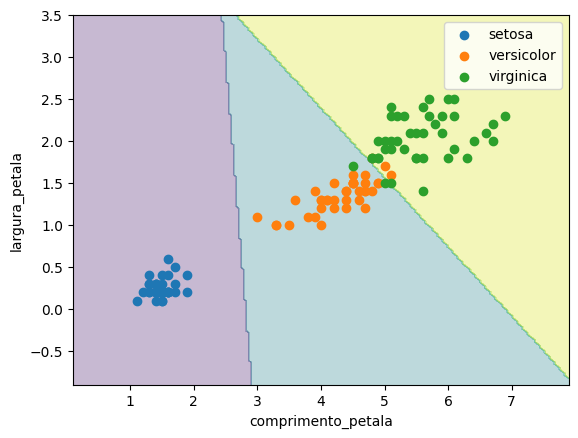

In [9]:
import numpy as np
import matplotlib.pyplot as plt

X_train_2d = X_train[["comprimento_petala", "largura_petala"]]
clf_log_2d = LogisticRegression(max_iter=200)
clf_log_2d.fit(X_train_2d, y_train)

x_min, x_max = X_train_2d["comprimento_petala"].min() - 1, X_train_2d["comprimento_petala"].max() + 1
y_min, y_max = X_train_2d["largura_petala"].min() - 1, X_train_2d["largura_petala"].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))

grid = pd.DataFrame({
    "comprimento_petala": xx.ravel(),
    "largura_petala": yy.ravel(),
})
especies = sorted(y_train.unique())
mapa_especie = {especie: i for i, especie in enumerate(especies)}
Z = clf_log_2d.predict(grid)
Z_num = pd.Series(Z).map(mapa_especie).values.reshape(xx.shape)

plt.contourf(xx, yy, Z_num, alpha=0.3)
for especie in especies:
    subset = X_train_2d[y_train == especie]
    plt.scatter(subset["comprimento_petala"], subset["largura_petala"], label=especie)
plt.xlabel("comprimento_petala")
plt.ylabel("largura_petala")
plt.legend()
plt.show()

As regiões coloridas mostram o que o modelo prevê em cada ponto do espaço; os pontos são as flores reais de treino. Onde uma região colorida "engole" pontos de outra cor, o modelo tende a errar — repare especialmente na fronteira entre versicolor e virginica, espécies que costumam ter medidas mais parecidas entre si.

## Exercício 2 — Alterando `max_iter`

Treine uma nova Regressão Logística, alterando `max_iter` para um valor bem menor (por exemplo, `max_iter=1`) e depois para um valor bem maior (por exemplo, `max_iter=1000`). Gere as predições em cada caso e observe se o treinamento continua funcionando normalmente.

Em uma célula de texto, registre: o que aconteceu com `max_iter=1`? O treinamento avisou algo? As predições mudaram de forma perceptível entre os três valores testados? Qual é, na sua opinião, o papel desse parâmetro?

In [10]:
# Escreva seu código aqui
from sklearn.linear_model import LogisticRegression

clf_log = LogisticRegression(max_iter=1000)
clf_log.fit(X_train, y_train)
pred_log = clf_log.predict(X_test)

pred_log[:10]


array(['virginica', 'versicolor', 'versicolor', 'setosa', 'virginica',
       'setosa', 'versicolor', 'versicolor', 'setosa', 'setosa'],
      dtype=object)

Quando alterei para `max_iter`, foi emitido um aviso de que o limite de alterações foi atingido (`STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT`). Acredito que esse warning foi emitido pelo peso ter sido interrompido antes do ajuste ideal, porque quando coloquei 1000, o aviso sumiu e tudo correu normalmente.

## Exemplo guiado 3 — Árvore de Decisão

A Árvore de Decisão aprende uma sequência de perguntas do tipo "essa feature é maior ou menor que um valor?", como no jogo de 20 perguntas, até chegar a uma classe.

In [11]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

clf_tree = DecisionTreeClassifier(max_depth=3, random_state=42)
clf_tree.fit(X_train, y_train)
pred_tree = clf_tree.predict(X_test)

pred_tree[:10]

array(['virginica', 'versicolor', 'versicolor', 'setosa', 'virginica',
       'setosa', 'versicolor', 'versicolor', 'setosa', 'setosa'],
      dtype=object)

`max_depth=3` limita a árvore a, no máximo, três níveis de perguntas — isso evita que ela cresça até decorar o treino (*overfitting*). `random_state=42` garante que empates entre perguntas igualmente boas sejam resolvidos sempre da mesma forma, tornando a árvore reproduzível.

Agora vamos visualizar a estrutura da árvore treinada.

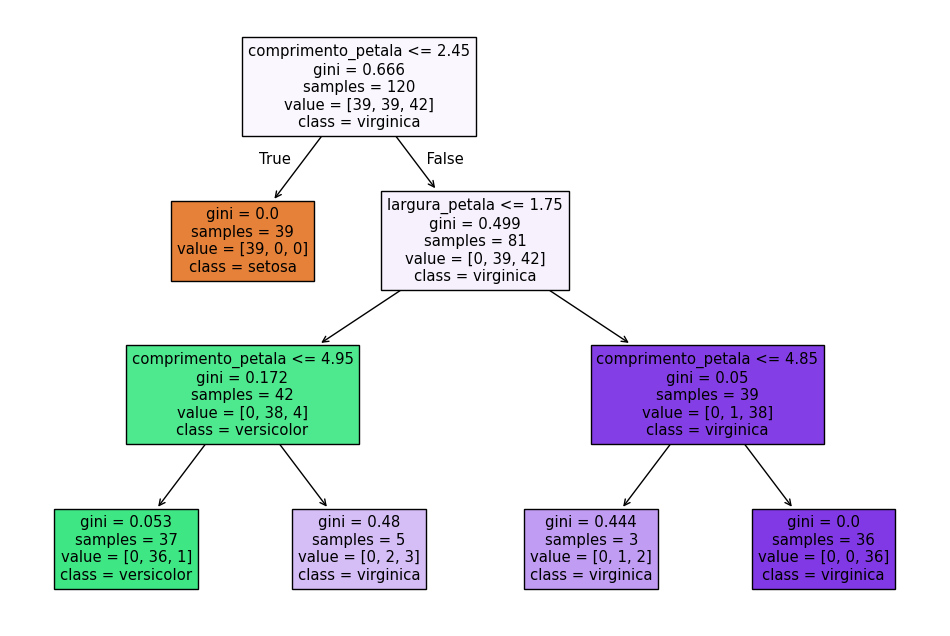

In [12]:
plt.figure(figsize=(12, 8))
plot_tree(
    clf_tree,
    feature_names=X_train.columns,
    class_names=clf_tree.classes_,
    filled=True,
)
plt.show()

Cada retângulo (nó) mostra a pergunta feita ali, quantas amostras de treino chegaram até esse ponto e como elas se distribuem entre as espécies. Os ramos representam as respostas "sim"/"não". Os retângulos nas pontas, sem mais ramos, são as folhas: cada uma representa uma decisão final de espécie. Quanto mais forte a cor de um nó, mais dominante é a maioria naquele grupo.

## Exercício 3 — Alterando `max_depth`

Treine novas árvores de decisão com `max_depth=1` e depois com `max_depth=None` (sem limite). Gere `plot_tree` para cada uma e compare visualmente com a árvore de `max_depth=3` do exemplo guiado.

Em uma célula de texto, responda: como a árvore mudou visualmente entre os três valores de `max_depth`? As predições sobre `X_test` também mudaram? Qual configuração gerou a árvore mais simples?

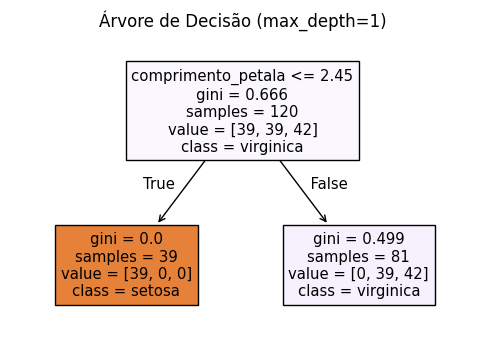

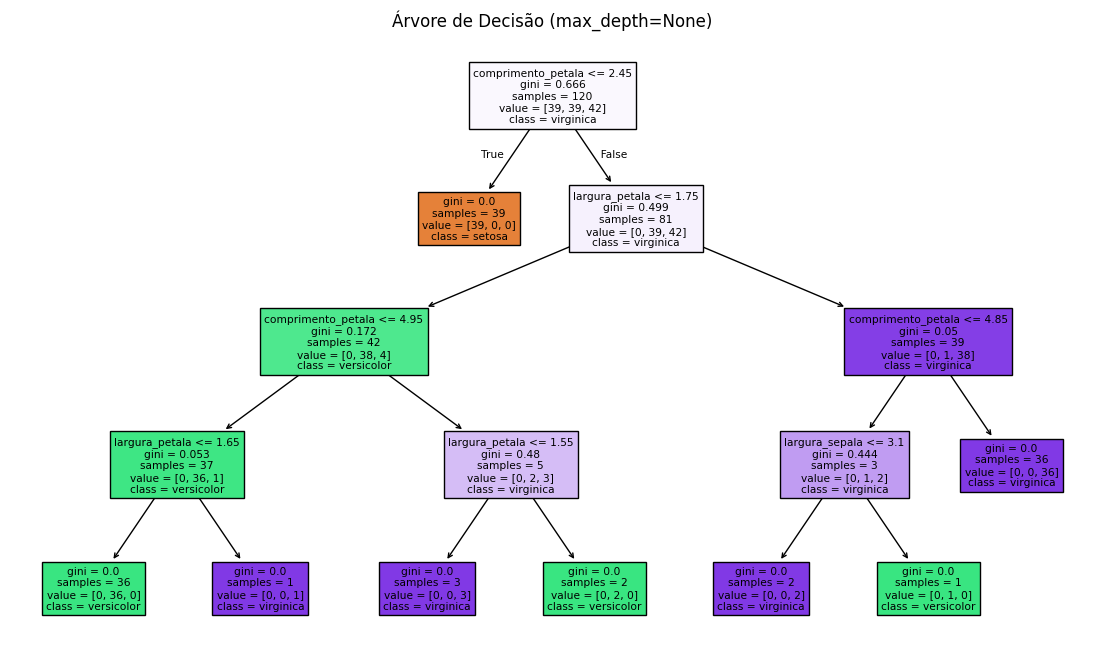

In [13]:
# Escreva seu código aqui
from sklearn.tree import DecisionTreeClassifier, plot_tree

clf_tree_1 = DecisionTreeClassifier(max_depth=1, random_state=42)
clf_tree_1.fit(X_train, y_train)
pred_tree = clf_tree_1.predict(X_test)

clf_tree_none = DecisionTreeClassifier(max_depth=None, random_state=42)
clf_tree_none.fit(X_train, y_train)
pred_tree = clf_tree_none.predict(X_test)

plt.figure(figsize=(6, 4))
plot_tree(
    clf_tree_1,
    feature_names=X_train.columns,
    class_names=clf_tree_1.classes_,
    filled=True,
)
plt.title("Árvore de Decisão (max_depth=1)")
plt.show()

print("\n")

plt.figure(figsize=(14, 8))
plot_tree(
    clf_tree_none,
    feature_names=X_train.columns,
    class_names=clf_tree_none.classes_,
    filled=True,
)
plt.title("Árvore de Decisão (max_depth=None)")
plt.show()

_(sua explicação em texto aqui)_

A menor de todas é a `max_depth=1`, já a de tamanho intermediário é a `max_depth=3`, e a maior de todas é a de `max_depth=None`.

As predições de `max_depth=1` mudam bastante em relação às outras duas, porque com tão pouca profundidade, as predições permanecem praticamente iguais, mostrando que aumentar muito a profundidade além de 3 não trouxe ganho prático para o teste.


## Exemplo guiado 4 — KNN (K-Nearest Neighbors)

O KNN classifica uma flor nova olhando para as `k` flores de treino mais parecidas com ela e escolhendo a espécie mais comum entre essas vizinhas.

In [14]:
from sklearn.neighbors import KNeighborsClassifier

clf_knn = KNeighborsClassifier(n_neighbors=5)
clf_knn.fit(X_train, y_train)
pred_knn = clf_knn.predict(X_test)

pred_knn[:10]

array(['virginica', 'versicolor', 'versicolor', 'setosa', 'virginica',
       'setosa', 'versicolor', 'versicolor', 'setosa', 'setosa'],
      dtype=object)

`n_neighbors=5` define o valor de `k`: quantas vizinhas de treino são consultadas para decidir a classe de cada flor nova. Diferente da Regressão Logística e da Árvore de Decisão, o `fit()` do KNN apenas guarda `X_train`/`y_train` em memória — o cálculo de fato acontece durante `predict()`.

Vamos visualizar, para uma flor específica de teste, quais vizinhos de treino o KNN considerou.

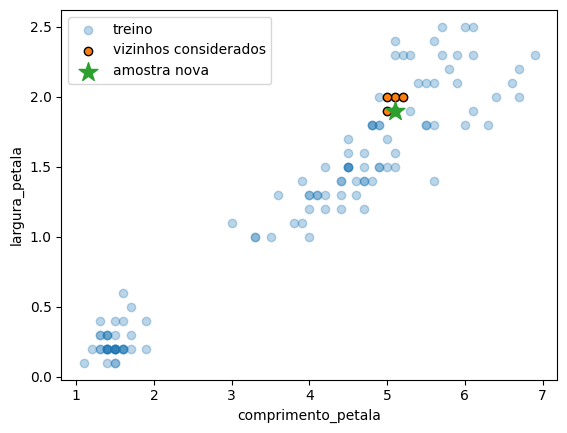

In [15]:
X_test_2d = X_test[["comprimento_petala", "largura_petala"]]
clf_knn_2d = KNeighborsClassifier(n_neighbors=5)
clf_knn_2d.fit(X_train_2d, y_train)

amostra = X_test_2d.iloc[[0]]
distancias, indices = clf_knn_2d.kneighbors(amostra)
vizinhos = X_train_2d.iloc[indices[0]]

plt.scatter(X_train_2d["comprimento_petala"], X_train_2d["largura_petala"], alpha=0.3, label="treino")
plt.scatter(vizinhos["comprimento_petala"], vizinhos["largura_petala"], edgecolor="black", label="vizinhos considerados")
plt.scatter(amostra["comprimento_petala"], amostra["largura_petala"], marker="*", s=200, label="amostra nova")
plt.xlabel("comprimento_petala")
plt.ylabel("largura_petala")
plt.legend()
plt.show()

`kneighbors()` devolve as distâncias e os índices das `k` flores de treino mais próximas da amostra escolhida. O gráfico destaca com contorno preto apenas os vizinhos considerados, e marca com uma estrela a flor nova. A predição do KNN para essa flor foi decidida pela espécie mais comum entre as flores destacadas.

## Exercício 4 — Alterando `n_neighbors`

Treine novos classificadores KNN com `n_neighbors=1` e depois com `n_neighbors=15`. Gere as predições em cada caso e compare com as predições de `n_neighbors=5` do exemplo guiado.

Em uma célula de texto, responda: as predições mudaram entre os três valores de `k` testados? O que você observa sobre o comportamento do modelo com `k` muito pequeno versus `k` muito grande?

In [16]:
# Escreva seu código aqui
from sklearn.neighbors import KNeighborsClassifier

clf_knn_1 = KNeighborsClassifier(n_neighbors=1)
clf_knn_1 = clf_knn_1.fit(X_train, y_train)
pred_knn_1 = clf_knn_1.predict(X_test)



clf_knn_15 = KNeighborsClassifier(n_neighbors=15)
clf_knn_15 = clf_knn_15.fit(X_train, y_train)
pred_knn_15 = clf_knn_15.predict(X_test)

print("Predições com k=1 (primeiras 10):")
print(pred_knn_1[:10])

print("\nPredições com k=5 (o mesmo do exemplo):")
print(pred_knn[:10])

print("\nPredições com k=15 (primeiras 10):")
print(pred_knn_15[:10])

Predições com k=1 (primeiras 10):
['virginica' 'versicolor' 'versicolor' 'setosa' 'virginica' 'setosa'
 'versicolor' 'versicolor' 'setosa' 'setosa']

Predições com k=5 (o mesmo do exemplo):
['virginica' 'versicolor' 'versicolor' 'setosa' 'virginica' 'setosa'
 'versicolor' 'versicolor' 'setosa' 'setosa']

Predições com k=15 (primeiras 10):
['virginica' 'versicolor' 'versicolor' 'setosa' 'virginica' 'setosa'
 'versicolor' 'versicolor' 'setosa' 'setosa']


Na prática, acabamos achando que as predições quase não mudaram entre k = 1, k = 5 e k = 15. Porém, quando pensamos que quando usamos k = 1 o modelo apenas observa um único vizinho, as coisas mudam. O classificador se torna muito mais vulnerável a flores mais diferentes, o que pode ocasionar em resultados errados. Já com k = 15, temos muitos vizinhos a serem consultados antes de uma decisão ser tomada. Isso é bom por evitar ruídos, mas caso o k auemnte muito, o modelo pode começar a ignorar particularidades de flores e acabar errando.

## Exemplo guiado 5 — Tabela comparativa

Vamos reunir, em uma única tabela, o valor real (`y_test`) e as predições dos três modelos, com colunas indicando se cada modelo acertou cada flor.

In [17]:
comparacao = pd.DataFrame({
    "real": y_test.values,
    "regressao_logistica": pred_log,
    "arvore_decisao": pred_tree,
    "knn": pred_knn,
})
comparacao["acerto_log"] = comparacao["real"] == comparacao["regressao_logistica"]
comparacao["acerto_arvore"] = comparacao["real"] == comparacao["arvore_decisao"]
comparacao["acerto_knn"] = comparacao["real"] == comparacao["knn"]

comparacao

,real,regressao_logistica,arvore_decisao,knn,acerto_log,acerto_arvore,acerto_knn
0,virginica,virginica,virginica,virginica,True,True,True
1,versicolor,versicolor,versicolor,versicolor,True,True,True
2,versicolor,versicolor,versicolor,versicolor,True,True,True
3,setosa,setosa,setosa,setosa,True,True,True
4,virginica,virginica,virginica,virginica,True,True,True
5,setosa,setosa,setosa,setosa,True,True,True
6,versicolor,versicolor,versicolor,versicolor,True,True,True
7,versicolor,versicolor,versicolor,versicolor,True,True,True
8,setosa,setosa,setosa,setosa,True,True,True
9,setosa,setosa,setosa,setosa,True,True,True


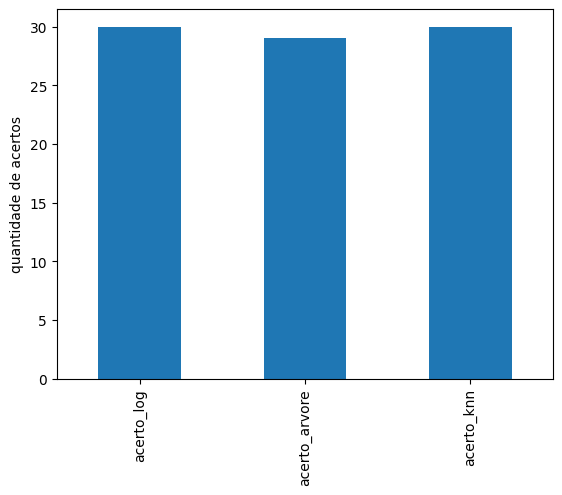

In [18]:
comparacao[["acerto_log", "acerto_arvore", "acerto_knn"]].sum().plot(kind="bar")
plt.ylabel("quantidade de acertos")
plt.show()

Essa tabela e esse gráfico não usam nenhuma métrica formal — são apenas uma contagem direta de acertos, olho no olho com os dados, para desenvolver uma intuição sobre o comportamento de cada modelo antes da M03-L04.

## Exercício 5 — Interpretando acertos e erros

Usando a tabela `comparacao`, responda em texto:

- Existe alguma flor em que os três modelos erraram ao mesmo tempo? Se sim, o que essas flores têm em comum, olhando suas features?
- Algum modelo parece ter cometido mais erros do que os outros, ainda que de forma qualitativa?
- Os erros parecem se concentrar em alguma espécie específica? Por quê, na sua opinião, isso pode acontecer?

In [27]:
# Use esta célula para explorar a tabela comparacao, se quiser
erros = comparacao[(~comparacao["acerto_log"])] | (~comparacao["acerto_arvore"]) | (~comparacao["acerto_knn"])
print("Flores com algum erro:", erros)

erros_gerais = comparacao[(~comparacao["acerto_log"])] & (~comparacao["acerto_arvore"]) & (~comparacao["acerto_knn"])
print("Flores em que TODOS erraram:", erros_gerais)

if not erros_gerais.empty:
  print("Características das flores em que TODOS erraram:")
  print(X_test.iloc[erros_gerais.index])

Flores com algum erro: Empty DataFrame
Columns: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, acerto_arvore, acerto_knn, acerto_log, arvore_decisao, knn, real, regressao_logistica]
Index: []

[0 rows x 37 columns]
Flores em que TODOS erraram: Empty DataFrame
Columns: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, acerto_arvore, acerto_knn, acerto_log, arvore_decisao, knn, real, regressao_logistica]
Index: []

[0 rows x 37 columns]


- **1.** Não existe nenhuma flor em que os três erraram ao mesmo tempo, mas imagino que quase sempre serão flores que possuem medidas intermediárias em que podem haver flores de duas ou mais espécimes diferentes que tenham tamanhos ou outras features semelhantes.

- **2.** O modelo que mais cometeu erros foi o `arvore`, com cerca de 1 erro.

- **3.** Os erros costumam se concentrar na diferenciação entre as flores versicolor e virginica, por possuirem features bem semelhantes (neste caso, o tamanho).

## Exemplo de erro comum

A seguir, três erros comuns ao usar o padrão `fit()`/`predict()`. As células abaixo estão com erros propositais — rode-as (com cuidado, uma de cada vez) e observe o que acontece.

In [20]:
from sklearn.linear_model import LogisticRegression

# Erro 1: chamar predict() antes de fit()
clf_sem_treino = LogisticRegression(max_iter=200)
clf_sem_treino.fit(X_train, y_train)
clf_sem_treino.predict(X_test)

NotFittedError: This LogisticRegression instance is not fitted yet. Call 'fit' with appropriate arguments before using this estimator.

In [ ]:
# Erro 2: usar X_train no lugar de X_test em predict()
pred_errado = clf_log.predict(X_train)
pred_errado[:10]

In [ ]:
# Erro 3: comparar predições de X_test com y_train
comparacao_errada = pred_log == y_train.values
comparacao_errada[:10]

O primeiro erro gera uma exceção: o modelo ainda não foi treinado, então não existe nenhum conhecimento interno para usar na predição. O segundo erro não gera nenhuma exceção — o código roda normalmente —, mas o resultado deixa de significar o que deveria: prever sobre `X_train` mostra o quanto o modelo decorou os próprios exemplos de treino, não sua capacidade de generalizar. O terceiro erro também roda sem exceção, mas a comparação não faz sentido: os tamanhos costumam ser diferentes, e mesmo quando coincidem, não existe correspondência linha a linha entre uma predição sobre `X_test` e os rótulos de `X_train`.

## Exercício de correção de erro

Corrija, na célula abaixo, os três erros apresentados: treine `clf_sem_treino` antes de usá-lo, gere a predição sobre `X_test` (não `X_train`), e compare o resultado apenas com `y_test`.

Em uma célula de texto, explique por que cada uma das três versões incorretas estava errada.

In [36]:
# Escreva a versão corrigida aqui
clf_sem_treino = LogisticRegression(max_iter=200)
clf_sem_treino.fit(X_train, y_train)

pred_x = clf_sem_treino.predict(X_test)

comp_sem_treino = pred_x == y_test.values
print(comp_sem_treino[:10])


[ True  True  True  True  True  True  True  True  True  True]


- **Erro 1**: O modelo não foi treinado, e quando não executamos o fit(), ele não calcula corretamente usando suas métricas e acaba não tendo regras para realizar predições, disparando um erro de execução.

- **Erro 2**: O código roda normalmente, mas usar os dados de treino para avaliar o modelo mede apenas a capacidade de memorização das amostras, sem testar com os dados novos. O certo para validação é utilizar X_test.

- **Erro 3**: As predições foram geradas para as flores do (X_test), portanto a comparação deve ser feita os rótulos reais correspondentes, que seriam o (y_test). Comparar com y_train traz tamanhos diferentes e sem correspondência entre as amostras.  

## Desafio extra (opcional)

Para quem quiser ir além do conteúdo obrigatório desta lição:

- treine uma SVM (`SVC` do `sklearn.svm`) com o mesmo padrão `fit()`/`predict()` já usado nesta lição, e acrescente suas predições à tabela comparativa;
- experimente outros valores de `k` no KNN, além dos já testados no Exercício 4, e observe se as predições continuam mudando.

In [47]:
# Desafio extra: SVM
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
# Escreva seu código aqui

clf_svm = SVC(random_state=42)
clf_svm.fit(X_train, y_train)
pred_svm = clf_svm.predict(X_test)

comparacao["svm"] = pred_svm
comparacao["acerto_svm"] = comparacao["real"] == comparacao["svm"]

clf_knn_3 = KNeighborsClassifier(n_neighbors=3).fit(X_train, y_train)
pred_knn_3 = clf_knn_3.predict(X_test)
clf_knn_7 = KNeighborsClassifier(n_neighbors=7).fit(X_train, y_train)
pred_knn_7 = clf_knn_7.predict(X_test)

print("Total de acertos de cada modelo:")
colunas_acertadas = ["acerto_log", "acerto_arvore", "acerto_knn", "acerto_svm"]
print(comparacao[colunas_acertadas].sum())

print("Variações do KNN:")
print("Predições de k=3 iguais a k=5?", (pred_knn_3 == pred_knn).all())
print("Predições de k=7 iguais a k=5?", (pred_knn_7 == pred_knn).all())
print("Predições de k=3 iguais a k=7?", (pred_knn_3 == pred_knn_7).all())


Total de acertos de cada modelo:
acerto_log       30
acerto_arvore    29
acerto_knn       30
acerto_svm       30
dtype: int64
Variações do KNN:
Predições de k=3 iguais a k=5? True
Predições de k=7 iguais a k=5? True
Predições de k=3 iguais a k=7? True


## Reflexão final

Em texto, responda:

- O que muda entre "aprender uma regra" (Regressão Logística e Árvore de Decisão) e "consultar vizinhos" (KNN)?
- Qual dos três algoritmos foi mais fácil de entender intuitivamente? Por quê?
- Por que a comparação desta lição foi apenas qualitativa, sem métricas formais como acurácia?
- Como você usaria `X_train`, `X_test`, `y_train` e `y_test` corretamente, em suas próprias palavras?

**Resposta:**
- Quando se "aprende uma regra" com a Regressão Logística e Árvore de Decisão, o modelo aprende os parâmetros que serão usados quando usamos `fit` no treinamento. Já com o KNN, não se cria uma regra no treinamento, apenas se memoriza as amostras e então, depois de consultar os vizinhos, se calcula e então se decide pela maioria dos votos.
- Acredito que a Árvore de Decisão foi o mais intuitivo, pois se assemelha muito a um fluxograma de perguntas. Também achei o KNN muito interessante.
- Acredito que tenha sido porque o objetivo dessa lição era mostrar uma parte mais visual de tudo, sem focar em números soltos, mas nos mostrando o que acontece visualmente falando.
- Eu usaria os `train`s na parte de `fit` para treinarmos e ensinarmos o modelo. Depois de treinarmos, usamos o predict. Nele, usamos o `x_test` para gerar as previsões. Então, no final, com o objetivo de compararmos os resultados, nós usamos o `y_test`.

## Checklist de conclusão

- [x] Abri o notebook no Google Colab.
- [x] Salvei uma cópia no meu Google Drive.
- [x] Executei as células de texto e código.
- [x] Carreguei `X_treino.csv`, `X_teste.csv`, `y_treino.csv` e `y_teste.csv` da M03-L02.
- [x] Confirmei que cada conjunto `X` possui a mesma quantidade de linhas que seu `y` correspondente, sem refazer o `train_test_split`.
- [x] Treinei pelo menos dois classificadores com `fit()`.
- [x] Gerei predições com `predict()`.
- [x] Comparei os valores previstos com `y_test`.
- [x] Corrigi os erros propostos.
- [x] Preenchi a reflexão final.

## O que entregar

Ao final desta lição, mantenha salvos em sua cópia do notebook:

- todas as células de texto e código executadas, incluindo os exercícios, a correção de erros e a reflexão final;
- a tabela comparativa com as predições dos três modelos;
- os gráficos gerados ao longo da lição (fronteira de decisão, árvore, vizinhos do KNN).

Não é necessário enviar nada além da sua cópia do notebook salva no Google Drive, a menos que seu monitor indique outro procedimento.